# ODD Specification and Runtime Monitoring

**Module 07 · Runtime Assurance and Operations** · Notebook 1 of 3

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/07_Runtime_Assurance_and_Operations/01_odd_and_runtime_monitoring.ipynb)

| Level | Time | Prerequisites | Standards |
|---|---|---|---|
| Intermediate | ~60 min | [SAE levels and ODD](../01_Perception/01_sae_levels_and_odd.ipynb), [SOTIF fundamentals](../04_SOTIF_ISO21448/01_sotif_fundamentals.ipynb) | ISO 34503:2023, SAE J3016 (2021), UN R157, UL 4600 (3rd ed., 2023) |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

After this notebook you will be able to:

- define an Operational Design Domain (ODD) with SAE J3016 terminology and structure it with the ISO 34503:2023 taxonomy;
- explain who performs the DDT fallback at each automation level, and distinguish a *minimal risk condition* (MRC) from a *minimum risk manoeuvre* (MRM);
- implement a runtime ODD monitor with hysteresis, dwell and confirmation times, driving a NOMINAL → DEGRADED → MRM → MRC state machine;
- reproduce the UN R157 transition-demand timings for a Level 3 ALKS;
- define leading and lagging *safety performance indicators* (SPIs) in the sense of UL 4600 and evaluate them with confidence intervals.

The introduction to ODDs in [01_Perception/01](../01_Perception/01_sae_levels_and_odd.ipynb) is assumed; here we focus on specification, monitoring and fallback at runtime.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
# Okabe-Ito colour-blind-safe palette
OI = {"blue": "#0072B2", "orange": "#E69F00", "green": "#009E73", "red": "#D55E00",
      "purple": "#CC79A7", "sky": "#56B4E9", "yellow": "#F0E442", "black": "#000000"}
pd.set_option("display.max_colwidth", 80)
print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.5.4 | pandas 3.1.0


---
## 1. What an ODD is — and what it is not

**Definition (SAE J3016:2021).** The ODD is the set of operating conditions under which a given driving automation system or feature is specifically designed to function, including, but not limited to, environmental, geographical and time-of-day restrictions, and/or the requisite presence or absence of certain traffic or roadway characteristics.

Three points are frequently confused:

1. **The ODD is a design claim, not a guarantee.** It states where the manufacturer *intends* the feature to work. The safety argument must still show that (i) the system is acceptably safe inside the ODD, (ii) it detects when it is leaving or has left the ODD, and (iii) it reaches a safe state when it has.
2. **ODD vs. SOTIF triggering conditions.** Triggering conditions (ISO 21448:2022) occur *inside* the ODD as well as at its boundary — a low sun or a pedestrian in dark clothing at night is usually within the ODD. Narrowing the ODD can remove some triggering conditions, but SOTIF analysis of the remaining ones is still required.
3. **ODD vs. ASIL.** HARA (ISO 26262-3) rates hazardous events in *operational situations*; ODD exit and the subsequent fallback are themselves operational situations to be rated. ASILs are therefore not "valid only inside the ODD".

ISO 34503:2023 additionally distinguishes the ODD (what the system is designed for) from the **target operational domain (TOD)** — the conditions the vehicle will actually encounter in its intended deployment. The gap between TOD and ODD is exactly what the runtime monitor has to police.

### 1.1 Fallback by automation level

The *dynamic driving task (DDT) fallback* is the response to a system failure or an ODD exit. Who performs it depends on the level (J3016):

In [2]:
fallback = pd.DataFrame([
    ["0-2", "Driver (always)", "Driver", "None: the driver supervises and is the fallback at all times",
     "No ODD-exit handover; the driver is already driving"],
    ["3", "ADS (within ODD)", "Fallback-ready user",
     "ADS issues a request to intervene; under UN R157 an ALKS escalates the transition demand and, "
     "if the driver does not respond, performs an MRM to standstill",
     "Residual risk depends on take-over performance"],
    ["4", "ADS (within ODD)", "ADS", "ADS performs the DDT fallback and reaches an MRC without a human",
     "ADS must detect ODD exit and reach an MRC unaided"],
    ["5", "ADS (unlimited ODD)", "ADS", "As level 4, but with no ODD limitation", "Not deployed"],
], columns=["SAE level", "Performs the DDT", "DDT fallback", "What happens at ODD exit / failure", "Safety implication"])
fallback

,SAE level,Performs the DDT,DDT fallback,What happens at ODD exit / failure,Safety implication
0,0-2,Driver (always),Driver,None: the driver supervises and is the fallback at all times,No ODD-exit handover; the driver is already driving
1,3,ADS (within ODD),Fallback-ready user,ADS issues a request to intervene; under UN R157 an ALKS escalates the trans...,Residual risk depends on take-over performance
2,4,ADS (within ODD),ADS,ADS performs the DDT fallback and reaches an MRC without a human,ADS must detect ODD exit and reach an MRC unaided
3,5,ADS (unlimited ODD),ADS,"As level 4, but with no ODD limitation",Not deployed


**Terminology.**

- **Minimal risk condition (MRC)** — SAE J3016: a stable, stopped condition to which a user or an ADS may bring a vehicle after performing the DDT fallback, in order to reduce the risk of a crash when a given trip cannot or should not be continued. It is an *end state*.
- **Minimum risk manoeuvre (MRM)** — UN R157 §2.7: "a procedure aimed at minimising risks in traffic, which is automatically performed by the system after a transition demand without driver response or in the case of a severe ALKS or vehicle failure". It is the *manoeuvre* that leads to the MRC.
- **Transition demand** (UN R157 §2.2) — the system's request to the driver to take back the DDT. A transition demand is *not* an MRC strategy; it precedes a possible MRM.

> J3016 uses "minimal" (condition); UN R157 uses "minimum" (manoeuvre). Both spellings appear in the literature.

---
## 2. Specifying the ODD with ISO 34503:2023

ISO 34503:2023 (*Road vehicles — Test scenarios for automated driving systems — Specification for operational design domain*) gives a hierarchical taxonomy and a definition format. It is aimed mainly at Level 3 and 4 ADS. Its scope explicitly excludes test procedures for ODD attributes and the *requirements* for monitoring them — those are the developer's job, which is what this notebook demonstrates. (The vocabulary is in ISO 34501:2022 and the scenario-based safety-evaluation framework in ISO 34502:2022.)

The taxonomy has **three top-level groups** (Clauses 9–11):

| Top-level group | Sub-categories (ISO 34503:2023) |
|---|---|
| **Scenery elements** (static) | zones; drivable area (type, geometry, lane specification, signs, edge, surface); junctions (roundabouts, intersections); basic road structures; special structures; temporary drivable area structures |
| **Environmental conditions** | weather (ambient temperature, wind, rainfall, snowfall); particulates; illumination; connectivity |
| **Dynamic elements** | traffic agents; subject vehicle (e.g. its speed) |

Clause 12 specifies the definition format: statements can be **inclusive** ("the ODD includes …"), **exclusive** ("… except …") or **conditional**, must use objective boundaries, and must stay human-readable. The same three-group structure is used in BSI PAS 1883:2020. Note that connectivity is an *environmental condition*, and the subject vehicle's speed is a *dynamic element* — not separate top-level categories.

Below is an illustrative ODD for a motorway ADS feature. **The values are hypothetical** (chosen for teaching) and are not any manufacturer's ODD.

In [3]:
# Illustrative ODD for a motorway ADS feature, structured by the three top-level groups of ISO 34503:2023.
# The values are hypothetical (chosen for teaching) and are NOT any manufacturer's ODD.
odd_spec = {
    # attribute: (ISO 34503 group, sub-category, kind, OK limit, OUT limit, hysteresis, unit)
    #   kind "max": larger is worse (OK if v <= ok, MARGINAL if ok < v <= out, OUT if v > out)
    #   kind "min": smaller is worse (OK if v >= ok, MARGINAL if out <= v < ok, OUT if v < out)
    "rainfall":      ("Environmental conditions", "Weather - rainfall",   "max", 8.0,  16.0, 2.0,  "mm/h"),
    "visibility":    ("Environmental conditions", "Particulates / illumination", "min", 200.0, 100.0, 30.0, "m"),
    "loc_confidence":("Scenery / subject vehicle", "Drivable area (mapped) + localisation", "min", 0.95, 0.85, 0.01, "-"),
}
categorical_odd = pd.DataFrame([
    ["Scenery", "Zones", "Geofenced motorway sections listed in the route network (include)"],
    ["Scenery", "Drivable area", "Motorway, 2-4 lanes per direction, hard shoulder present (include); toll plazas (exclude)"],
    ["Scenery", "Junctions", "Grade-separated entries/exits only (include); at-grade intersections (exclude)"],
    ["Scenery", "Temporary drivable area structures", "Road works zones (exclude -> planned ODD exit)"],
    ["Environmental conditions", "Weather", "Rainfall <= 16 mm/h; snowfall (exclude); ambient temperature -20...+45 degC"],
    ["Environmental conditions", "Particulates", "Meteorological visibility >= 100 m"],
    ["Environmental conditions", "Illumination", "Day and night (include)"],
    ["Environmental conditions", "Connectivity", "Not required (positioning via on-board GNSS/IMU + map)"],
    ["Dynamic elements", "Traffic agents", "Motorised traffic; pedestrians on carriageway (exclude -> handled as hazard)"],
    ["Dynamic elements", "Subject vehicle", "Speed 0-100 km/h"],
], columns=["ISO 34503 group", "Sub-category", "Illustrative ODD statement (inclusion / exclusion)"])
categorical_odd

,ISO 34503 group,Sub-category,Illustrative ODD statement (inclusion / exclusion)
0,Scenery,Zones,Geofenced motorway sections listed in the route network (include)
1,Scenery,Drivable area,"Motorway, 2-4 lanes per direction, hard shoulder present (include); toll pla..."
2,Scenery,Junctions,Grade-separated entries/exits only (include); at-grade intersections (exclude)
3,Scenery,Temporary drivable area structures,Road works zones (exclude -> planned ODD exit)
4,Environmental conditions,Weather,Rainfall <= 16 mm/h; snowfall (exclude); ambient temperature -20...+45 degC
5,Environmental conditions,Particulates,Meteorological visibility >= 100 m
6,Environmental conditions,Illumination,Day and night (include)
7,Environmental conditions,Connectivity,Not required (positioning via on-board GNSS/IMU + map)
8,Dynamic elements,Traffic agents,Motorised traffic; pedestrians on carriageway (exclude -> handled as hazard)
9,Dynamic elements,Subject vehicle,Speed 0-100 km/h


For runtime monitoring we need *quantitative* attributes with explicit limits. Each monitored attribute gets an **OK limit** (inside the ODD with margin), an **ODD boundary** (beyond which the feature must not operate) and a **hysteresis** width, explained in Section 3.

In [4]:
pd.DataFrame([
    {"attribute": k, "ISO 34503 group": v[0], "sub-category": v[1], "worse when": "higher" if v[2] == "max" else "lower",
     "OK limit": v[3], "ODD boundary (OUT)": v[4], "hysteresis": v[5], "unit": v[6]}
    for k, v in odd_spec.items()])

,attribute,ISO 34503 group,sub-category,worse when,OK limit,ODD boundary (OUT),hysteresis,unit
0,rainfall,Environmental conditions,Weather - rainfall,higher,8.00,16.00,2.00,mm/h
1,visibility,Environmental conditions,Particulates / illumination,lower,200.00,100.00,30.00,m
2,loc_confidence,Scenery / subject vehicle,Drivable area (mapped) + localisation,lower,0.95,0.85,0.01,-


---
## 3. Runtime ODD monitoring with a degradation state machine

### 3.1 Architecture

```
 sensors / map / GNSS        attribute estimators          ODD monitor                   decision
 ───────────────────  ──►  rainfall, visibility,   ──►  OK / MARGINAL / OUT     ──►  NOMINAL ─► DEGRADED
                            localisation confidence      per attribute, with               │          │
                                                         hysteresis + debounce             ▼          ▼
                                                                                          MRM ───► MRC (standstill)
```

- **NOMINAL** — all attributes OK; full *maximum operational speed* (100 km/h here).
- **DEGRADED** — at least one attribute MARGINAL: still inside the ODD, but with reduced margin. The system lowers its maximum operational speed (60 km/h here) and increases headway. UN R157 §2.9.2 uses exactly this idea: the maximum operational speed is selected "under current environmental and sensor conditions".
- **MRM** — an attribute has been OUT for the confirmation time: the system decelerates in lane (R157 §5.5.1 aims at ≤ 4.0 m/s²; we use 3.0 m/s²) and activates the hazard warning lights.
- **MRC** — standstill. In R157 an MRM is terminated only when the driver deactivates the system or the vehicle has stopped (§5.5.4), so our MRM is *latching*.

### 3.2 Why hysteresis, dwell and confirmation times?

Attribute estimates are noisy. With a single threshold, an estimate hovering around the limit makes the mode — and therefore the speed — oscillate ("chattering"). Three standard remedies:

- **Hysteresis**: enter MARGINAL at 8 mm/h, but leave it only below 8 − 2 = 6 mm/h.
- **Dwell time**: remain DEGRADED until all attributes have been OK for 20 s.
- **Confirmation (debounce) time**: require OUT for 2 s before starting an MRM. This rejects single-sample noise but *delays* the reaction, so the ODD boundary used by the monitor must leave margin to the true capability limit.

### 3.3 Simulated drive

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

A 25-minute motorway drive: moderate rain hovering around the OK limit, a fog bank, a short localisation degradation (e.g. GNSS shadowing) and finally a heavy downpour that leaves the ODD.

In [5]:
DT = 1.0                    # s
T = 1500                    # s (25 min drive)
t = np.arange(0, T, DT)

def bump(t, start, end, peak):
    """Raised-cosine bump between start and end (0 outside)."""
    x = np.clip((t - start) / (end - start), 0, 1)
    return peak * 0.5 * (1 - np.cos(2 * np.pi * x)) * ((t >= start) & (t <= end))

def make_conditions(rng, rain_events, fog_events, loc_dips, T=T):
    t = np.arange(0, T, DT)
    rain = np.zeros_like(t, dtype=float)
    for s, e, p in rain_events:
        rain += bump(t, s, e, p)
    # slow natural variability of rain intensity (smoothed noise), only where it rains
    wiggle = np.convolve(rng.normal(0, 1.0, t.size), np.ones(30) / 30, mode="same") * 4
    rain = np.clip(rain + np.where(rain > 1, wiggle, 0), 0, None)
    fog = np.ones_like(t, dtype=float) * 1000.0
    for s, e, vmin in fog_events:
        fog = np.minimum(fog, 1000 - bump(t, s, e, 1000 - vmin))
    vis = np.minimum(fog, 1000 * np.exp(-rain / 10))     # heavy rain also reduces visibility
    loc = np.full_like(t, 0.99, dtype=float)
    for s, e, depth in loc_dips:
        loc -= bump(t, s, e, depth)
    return pd.DataFrame({"t": t, "rainfall": rain, "visibility": vis, "loc_confidence": loc})

truth = make_conditions(rng,
                        rain_events=[(250, 750, 9.5), (1200, 1700, 26.0)],
                        fog_events=[(820, 1060, 150.0)],
                        loc_dips=[(1080, 1160, 0.08)])

def measure(truth, rng):
    """On-board estimates of the ODD attributes (noisy)."""
    m = truth.copy()
    m["rainfall"] = np.clip(truth["rainfall"] + rng.normal(0, 0.8, len(truth)), 0, None)
    m["visibility"] = truth["visibility"] * np.exp(rng.normal(0, 0.08, len(truth)))
    m["loc_confidence"] = np.clip(truth["loc_confidence"] + rng.normal(0, 0.005, len(truth)), 0, 1)
    return m

meas = measure(truth, rng)
truth.describe().loc[["min", "max"]].round(2)

,t,rainfall,visibility,loc_confidence
min,0.0,0.00,68.17,0.91
max,1499.0,26.86,1000.00,0.99


The monitor and the state machine:

In [6]:
LEVELS = {0: "OK", 1: "MARGINAL", 2: "OUT"}
V_NOMINAL, V_DEGRADED = 100 / 3.6, 60 / 3.6     # m/s: nominal and reduced 'maximum operational speed'
A_MRM = 3.0                                     # m/s^2 MRM deceleration (R157 aims at <= 4.0 m/s^2)

def raw_level(kind, v, ok, out):
    if kind == "max":
        return 0 if v <= ok else (1 if v <= out else 2)
    return 0 if v >= ok else (1 if v >= out else 2)

class ODDMonitor:
    """Runtime ODD monitor + degradation state machine NOMINAL -> DEGRADED -> MRM -> MRC.

    hysteresis : if True, an attribute only returns to a better level once the estimate has
                 moved back past the threshold by the attribute's hysteresis width.
    dwell_s    : time an all-OK condition must persist before DEGRADED relaxes to NOMINAL.
    confirm_s  : time an OUT condition must persist before the MRM is triggered (debouncing).
    """
    def __init__(self, spec, hysteresis=True, dwell_s=20.0, confirm_s=2.0):
        self.spec, self.hyst, self.dwell_s, self.confirm_s = spec, hysteresis, dwell_s, confirm_s
        self.level = {k: 0 for k in spec}
        self.mode, self.ok_time, self.out_time, self.v = "NOMINAL", 0.0, 0.0, V_NOMINAL

    def attribute_level(self, name, v):
        _, _, kind, ok, out, h, _ = self.spec[name]
        new = raw_level(kind, v, ok, out)
        old = self.level[name]
        if self.hyst and new < old:                  # trying to improve: apply hysteresis band
            sign = -1 if kind == "max" else 1
            new = max(new, raw_level(kind, v - sign * h, ok, out))
        self.level[name] = new
        return new

    def step(self, obs, dt=DT):
        worst = max(self.attribute_level(k, obs[k]) for k in self.spec)
        self.out_time = self.out_time + dt if worst == 2 else 0.0
        self.ok_time = self.ok_time + dt if worst == 0 else 0.0
        if self.mode in ("MRM", "MRC"):              # an MRM is not aborted by the ADS (latching)
            pass
        elif worst == 2 and self.out_time >= self.confirm_s:
            self.mode = "MRM"
        elif worst >= 1:
            self.mode = "DEGRADED"
        elif self.mode == "DEGRADED" and self.ok_time < self.dwell_s:
            pass                                     # stay degraded until OK has persisted
        else:
            self.mode = "NOMINAL"
        # longitudinal speed control
        if self.mode == "MRM":
            self.v = max(0.0, self.v - A_MRM * dt)
            if self.v == 0.0:
                self.mode = "MRC"
        elif self.mode != "MRC":
            target = V_NOMINAL if self.mode == "NOMINAL" else V_DEGRADED
            self.v += np.clip(target - self.v, -2.0 * dt, 1.0 * dt)
        return self.mode, worst, self.v

def run_drive(meas, monitor):
    rows = []
    for r in meas.to_dict("records"):
        mode, worst, v = monitor.step(r)
        rows.append((r["t"], mode, worst, v))
        if mode == "MRC":
            break
    return pd.DataFrame(rows, columns=["t", "mode", "worst_level", "speed"])

We run two configurations on the *same* noisy measurements: a naive monitor (no hysteresis, no dwell, no debounce) and the robust one.

In [7]:
naive = run_drive(meas, ODDMonitor(odd_spec, hysteresis=False, dwell_s=0.0, confirm_s=0.0))
robust = run_drive(meas, ODDMonitor(odd_spec, hysteresis=True, dwell_s=20.0, confirm_s=2.0))

def ground_truth_level(df):
    return np.array([max(raw_level(v[2], row[k], v[3], v[4]) for k, v in odd_spec.items())
                     for row in df.to_dict("records")])

truth["true_level"] = ground_truth_level(truth)
t_true_out = truth.loc[truth["true_level"] == 2, "t"].min()

def summarise(name, log):
    changes = int((log["mode"] != log["mode"].shift()).sum() - 1)
    t_mrm = log.loc[log["mode"] == "MRM", "t"].min()
    t_mrc = log.loc[log["mode"] == "MRC", "t"].min()
    return {"monitor": name, "mode changes": changes,
            "time DEGRADED [s]": int((log["mode"] == "DEGRADED").sum() * DT),
            "MRM start [s]": t_mrm, "MRC reached [s]": t_mrc,
            "MRM start - true ODD exit [s]": t_mrm - t_true_out,
            "distance [km]": round(log["speed"].sum() * DT / 1000, 1)}

comparison = pd.DataFrame([summarise("naive (no hysteresis/dwell/debounce)", naive),
                           summarise("hysteresis + 20 s dwell + 2 s confirm", robust)])
print(f"True ODD exit (ground truth, first OUT sample): t = {t_true_out:.0f} s")
comparison

True ODD exit (ground truth, first OUT sample): t = 1340 s


,monitor,mode changes,time DEGRADED [s],MRM start [s],MRC reached [s],MRM start - true ODD exit [s],distance [km]
0,naive (no hysteresis/dwell/debounce),55,209,1329.0,1334.0,-11.0,34.4
1,hysteresis + 20 s dwell + 2 s confirm,11,340,1339.0,1344.0,-1.0,33.4


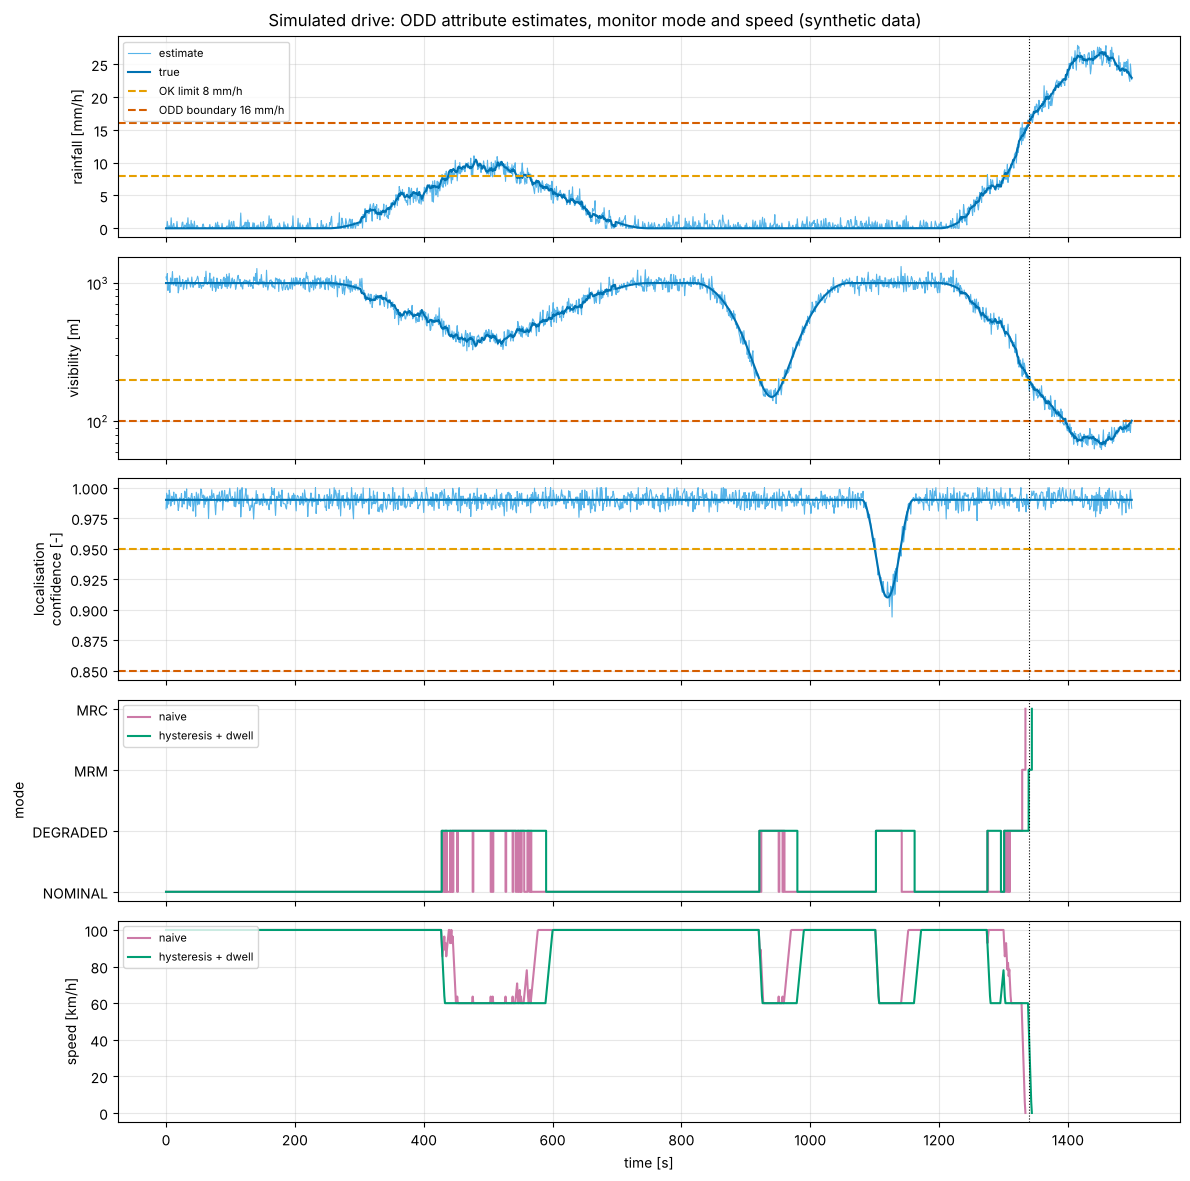

In [8]:
mode_code = {"NOMINAL": 0, "DEGRADED": 1, "MRM": 2, "MRC": 3}
fig, ax = plt.subplots(5, 1, figsize=(12, 12), sharex=True)
ax[0].plot(meas["t"], meas["rainfall"], color=OI["sky"], lw=0.8, label="estimate")
ax[0].plot(truth["t"], truth["rainfall"], color=OI["blue"], lw=1.5, label="true")
ax[0].axhline(8, color=OI["orange"], ls="--", label="OK limit 8 mm/h")
ax[0].axhline(16, color=OI["red"], ls="--", label="ODD boundary 16 mm/h")
ax[0].set_ylabel("rainfall [mm/h]")
ax[1].plot(meas["t"], meas["visibility"], color=OI["sky"], lw=0.8)
ax[1].plot(truth["t"], truth["visibility"], color=OI["blue"], lw=1.5)
ax[1].axhline(200, color=OI["orange"], ls="--"); ax[1].axhline(100, color=OI["red"], ls="--")
ax[1].set_ylabel("visibility [m]"); ax[1].set_yscale("log")
ax[2].plot(meas["t"], meas["loc_confidence"], color=OI["sky"], lw=0.8)
ax[2].plot(truth["t"], truth["loc_confidence"], color=OI["blue"], lw=1.5)
ax[2].axhline(0.95, color=OI["orange"], ls="--"); ax[2].axhline(0.85, color=OI["red"], ls="--")
ax[2].set_ylabel("localisation\nconfidence [-]")
for log, c, lab in [(naive, OI["purple"], "naive"), (robust, OI["green"], "hysteresis + dwell")]:
    ax[3].step(log["t"], log["mode"].map(mode_code), where="post", color=c, lw=1.5, label=lab)
    ax[4].plot(log["t"], log["speed"] * 3.6, color=c, lw=1.5, label=lab)
ax[3].set_yticks(list(mode_code.values()), list(mode_code.keys())); ax[3].set_ylabel("mode")
ax[4].set_ylabel("speed [km/h]"); ax[4].set_xlabel("time [s]")
for a in (ax[0], ax[3], ax[4]):
    a.legend(loc="upper left", fontsize=8)
for a in ax:
    a.axvline(t_true_out, color=OI["black"], lw=0.8, ls=":")
fig.suptitle("Simulated drive: ODD attribute estimates, monitor mode and speed (synthetic data)")
plt.tight_layout(); plt.show()

**Text summary** (computed from the logs above, for screen-reader users):

In [9]:
n, r = comparison.iloc[0], comparison.iloc[1]
print("Text summary (derived from the simulation above):")
print(f"- Naive monitor: {n['mode changes']} mode changes; robust monitor: {r['mode changes']}.")
if n["mode changes"] > r["mode changes"]:
    print(f"  Hysteresis and dwell time removed {n['mode changes'] - r['mode changes']} mode changes "
          f"({100 * (1 - r['mode changes'] / max(n['mode changes'], 1)):.0f} % fewer), i.e. less speed 'chattering'.")
for lab, row in [("naive", n), ("robust", r)]:
    dt_mrm = row["MRM start - true ODD exit [s]"]
    when = "before" if dt_mrm < 0 else "after"
    print(f"- {lab}: MRM started {abs(dt_mrm):.0f} s {when} the true ODD exit (t = {t_true_out:.0f} s).")
if min(n["MRM start - true ODD exit [s]"], r["MRM start - true ODD exit [s]"]) < 0:
    print("  An MRM *before* the true exit means estimation noise near the boundary pushed the estimate over the")
    print("  threshold while the true value was still inside the ODD: conservative here, but the same mechanism")
    print("  produces spurious MRMs elsewhere (see the SPI section).")
print(f"  The 2 s confirmation time shifted the MRM by {r['MRM start [s]'] - n['MRM start [s]']:.0f} s relative to the naive monitor;")
print("  any such delay must be budgeted in the safety argument (e.g. via margins between the OUT limit and the true capability limit).")
print(f"- Both drives end in an MRC (standstill); time spent DEGRADED: naive {n['time DEGRADED [s]']} s, "
      f"robust {r['time DEGRADED [s]']} s.")

Text summary (derived from the simulation above):
- Naive monitor: 55 mode changes; robust monitor: 11.
  Hysteresis and dwell time removed 44 mode changes (80 % fewer), i.e. less speed 'chattering'.
- naive: MRM started 11 s before the true ODD exit (t = 1340 s).
- robust: MRM started 1 s before the true ODD exit (t = 1340 s).
  An MRM *before* the true exit means estimation noise near the boundary pushed the estimate over the
  threshold while the true value was still inside the ODD: conservative here, but the same mechanism
  produces spurious MRMs elsewhere (see the SPI section).
  The 2 s confirmation time shifted the MRM by 10 s relative to the naive monitor;
  any such delay must be budgeted in the safety argument (e.g. via margins between the OUT limit and the true capability limit).
- Both drives end in an MRC (standstill); time spent DEGRADED: naive 209 s, robust 340 s.


**Discussion.**

- The robust monitor trades a small reaction delay for far fewer mode changes. Each mode change is a speed change that surrounding traffic must anticipate, so chattering is itself a hazard.
- Degradation buys time: in DEGRADED mode the vehicle is already slower, so the subsequent MRM is shorter.
- The MRM was triggered by *estimates*, not by the true state. The monitor's own performance (false alarms, missed or late exits) therefore needs its own evidence — this leads to the SPIs in Section 5.
- Real monitors also use *predictive* information (weather forecasts, map-announced road works as *planned events* in R157 terms) to start a transition or route change before the boundary is reached.

---
## 4. Level 3: the transition demand under UN R157

For an SAE Level 3 ALKS, the fallback-ready user is expected to take over. UN R157 (original text, E/ECE/TRANS/505/Rev.3/Add.156, and unchanged in the 01 series) fixes the sequence:

1. **Transition demand** — at least an optical signal plus an acoustic and/or haptic warning (§6.4.1(c)).
2. **Escalation** — at the latest 4 s after the start of the transition demand it must contain a constant or intermittent haptic warning (unless at standstill) and be escalated until it ends (§6.4.1(c), §5.4.3.2).
3. **Minimum risk manoeuvre** — if the driver has not taken over, an MRM is started *at the earliest* 10 s after the start of the transition demand (§5.4.4.1), or immediately in case of a severe ALKS or vehicle failure (§5.4.4.1.1). The vehicle decelerates in lane (aim ≤ 4.0 m/s²), the hazard lights are activated at the start of the MRM, and the MRM ends in standstill (§5.5).

For **planned events** (e.g. a motorway exit), the transition demand must be issued early enough that an MRM, if needed, would reach standstill before the event (§5.4.2.1).

The 01 series of amendments (adopted by WP.29 in June 2022, ECE/TRANS/WP.29/2022/59/Rev.1) raised the maximum speed from 60 km/h to **130 km/h** and added lane changes; a specified maximum speed above 60 km/h is permitted only if the ALKS can perform an *MRM lane change* (§5.2.3.1).

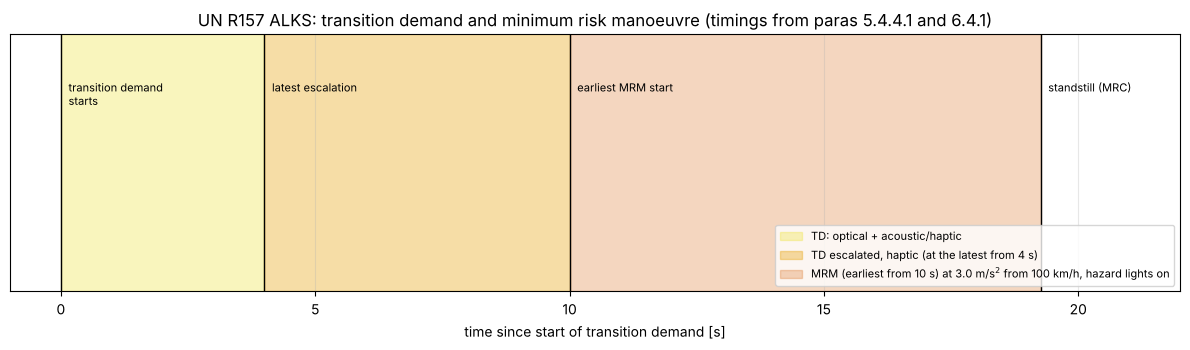

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.axvspan(0, 4, color=OI["yellow"], alpha=0.35, label="TD: optical + acoustic/haptic")
ax.axvspan(4, 10, color=OI["orange"], alpha=0.35, label="TD escalated, haptic (at the latest from 4 s)")
ax.axvspan(10, 10 + V_NOMINAL / A_MRM, color=OI["red"], alpha=0.25,
           label=f"MRM (earliest from 10 s) at {A_MRM} m/s$^2$ from 100 km/h, hazard lights on")
for x, txt in [(0, "transition demand\nstarts"), (4, "latest escalation"), (10, "earliest MRM start"),
               (10 + V_NOMINAL / A_MRM, "standstill (MRC)")]:
    ax.axvline(x, color=OI["black"], lw=1)
    ax.text(x + 0.15, 0.82, txt, fontsize=8, va="top")
ax.set_xlim(-1, 22); ax.set_ylim(0, 1); ax.set_yticks([])
ax.set_xlabel("time since start of transition demand [s]")
ax.set_title("UN R157 ALKS: transition demand and minimum risk manoeuvre (timings from paras 5.4.4.1 and 6.4.1)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

### 4.1 Why the 10 s matter: take-over performance

Human take-over times vary strongly. A meta-analysis of 129 studies (Zhang et al., 2019) found that mean take-over time is shorter with higher urgency, without a handheld device or a visual non-driving task, with prior take-over experience, and with auditory or vibrotactile (rather than visual-only) requests — and that the mean and standard deviation are highly correlated. Non-critical take-overs can take much longer than critical ones (Eriksson & Stanton, 2017), and driving performance can remain degraded after the take-over in complex traffic (Gold et al., 2016).

The Monte Carlo below shows the consequence for the residual risk. **The take-over distributions are synthetic** (illustrative only), constructed so that spread grows with the median as the meta-analysis reports.

In [11]:
# Illustrative data: synthetic take-over times, NOT measurements. Log-normal, with the mean and spread
# increasing together (Zhang et al. 2019 report that mean and SD of take-over time are highly correlated).
conditions = {"attentive, auditory + haptic TD": 2.5, "visual non-driving task": 4.5, "handheld device / drowsy": 7.0}
n_sim = 20_000
rows = []
for name, median in conditions.items():
    tot = rng.lognormal(mean=np.log(median), sigma=0.5, size=n_sim)
    rows.append({"condition (synthetic)": name, "median take-over [s]": round(np.median(tot), 1),
                 "95th percentile [s]": round(np.percentile(tot, 95), 1),
                 "P(no take-over before 10 s -> MRM)": round(np.mean(tot > 10), 4)})
tot_df = pd.DataFrame(rows)
display(tot_df)
worst = tot_df.loc[tot_df["P(no take-over before 10 s -> MRM)"].idxmax()]
print(f"In this synthetic example, the '{worst['condition (synthetic)']}' group would reach the MRM in "
      f"{100 * worst['P(no take-over before 10 s -> MRM)']:.1f} % of transition demands: the MRM is an expected "
      "operating outcome, not a rare corner case, and must itself be safe.")

,condition (synthetic),median take-over [s],95th percentile [s],P(no take-over before 10 s -> MRM)
0,"attentive, auditory + haptic TD",2.5,5.8,0.0027
1,visual non-driving task,4.5,10.2,0.0532
2,handheld device / drowsy,6.9,15.9,0.2344


In this synthetic example, the 'handheld device / drowsy' group would reach the MRM in 23.4 % of transition demands: the MRM is an expected operating outcome, not a rare corner case, and must itself be safe.


An L4 design removes the dependency on human readiness but must reach an MRC unaided in every situation within the ODD; an L3 design shifts part of the residual risk onto take-over performance. Neither is safer *per se* — the safety case has to show it for the specific design and ODD.

---
## 5. Safety performance indicators (SPIs)

UL 4600 (3rd ed., 2023) requires SPIs to keep a safety case valid during operation. As summarised by Ratiu et al. (2024), an SPI is a metric, supported by evidence, that uses a **threshold comparison to condition a claim** in the safety case. When an SPI is violated, the claim it supports is in doubt and the organisation must act (investigate, fix the design or update the safety case).

- **Lagging** indicators count harmful outcomes after the fact (collisions, injuries). They are what we ultimately care about, but they are rare — a small fleet may see none for a long time.
- **Leading** indicators measure precursors and the health of safety mechanisms (near misses, monitor false alarms, late ODD-exit detection, MRM frequency). Lagging indicators alone are therefore not sufficient to keep a safety case current (Ratiu et al., 2024).

For the runtime monitor, natural SPIs are its false-alarm rate, its late-detection rate and the MRM rate. Below we run the robust monitor on 150 random synthetic drives and evaluate SPIs with exact Poisson confidence intervals. A claim is considered supported only if the **upper** 95 % bound meets the threshold — a point estimate is not evidence.

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements. The thresholds are illustrative too: in a real project they are derived from the safety case.

In [12]:
# Fleet-level Monte Carlo: many synthetic drives with random weather, monitored by the robust monitor.
def random_drive(rng):
    rain = [(s, s + rng.uniform(300, 700), rng.choice([6.0, 10.0, 22.0], p=[0.5, 0.35, 0.15]))
            for s in rng.uniform(0, 1200, rng.integers(0, 3))]
    fog = [(s, s + rng.uniform(150, 400), rng.uniform(90, 400)) for s in rng.uniform(0, 1200, rng.integers(0, 2))]
    loc = [(s, s + rng.uniform(30, 120), rng.uniform(0.02, 0.10)) for s in rng.uniform(0, 1400, rng.integers(0, 2))]
    return make_conditions(rng, rain, fog, loc)

records = []
for i in range(150):
    tr = random_drive(rng)
    ms = measure(tr, rng)
    log = run_drive(ms, ODDMonitor(odd_spec))
    tl = ground_truth_level(tr.iloc[:len(log)])
    out_meas = (log["worst_level"].to_numpy() == 2)
    spurious = out_meas & (tl < 2)                         # monitor says OUT, truth is not OUT
    spurious_episodes = int(np.sum(np.diff(np.r_[0, spurious.astype(int)]) == 1))
    starts = np.flatnonzero(np.diff(np.r_[0, (tl == 2).astype(int)]) == 1)
    late = sum(1 for k in starts if not out_meas[max(0, k - 600):k + 6].any())   # not flagged within 5 s
    decel = -np.diff(log["speed"].to_numpy()) / DT
    records.append({"hours": len(log) * DT / 3600, "km": log["speed"].sum() * DT / 1000,
                    "mrm": int((log["mode"] == "MRM").any()),
                    "degraded_s": int((log["mode"] == "DEGRADED").sum() * DT),
                    "spurious_out_episodes": spurious_episodes, "true_exits": len(starts), "late_detections": late,
                    "hard_decel_events": int(np.sum(decel > 4.0))})
fleet = pd.DataFrame(records)
H, KM = fleet["hours"].sum(), fleet["km"].sum()

def poisson_ci(k, exposure, conf=0.95):
    """Exact (Garwood) two-sided CI for a Poisson rate (same as avsafety.validation.poisson_rate_interval)."""
    a = 1 - conf
    lo = 0.0 if k == 0 else stats.chi2.ppf(a / 2, 2 * k) / 2
    hi = stats.chi2.ppf(1 - a / 2, 2 * (k + 1)) / 2
    return lo / exposure, hi / exposure

spi_rows = []
def spi(name, kind, k, exposure, unit, threshold):
    rate = k / exposure
    lo, hi = poisson_ci(k, exposure)
    spi_rows.append({"SPI": name, "type": kind, "events": k, "rate": round(rate, 3),
                     "95% CI": f"[{lo:.3f}, {hi:.3f}]", "unit": unit, "threshold": threshold,
                     "claim supported?": "yes" if hi <= threshold else "no / not yet"})

spi("Spurious OUT detections (monitor OUT, truth not OUT)", "leading", int(fleet["spurious_out_episodes"].sum()), H, "per h", 0.5)
spi("True ODD exits not flagged OUT within 5 s", "leading", int(fleet["late_detections"].sum()), H, "per h", 0.1)
spi("MRM activations", "leading (precursor)", int(fleet["mrm"].sum()), H, "per h", 1.0)
spi("Hard decelerations > 4 m/s^2", "lagging (proxy)", int(fleet["hard_decel_events"].sum()), KM, "per km", 0.01)
spi_df = pd.DataFrame(spi_rows)
print(f"Synthetic fleet: {len(fleet)} drives, {H:.1f} h, {KM:.0f} km; "
      f"{100 * fleet['degraded_s'].sum() / (H * 3600):.1f} % of time in DEGRADED mode.")
spi_df

Synthetic fleet: 150 drives, 57.7 h, 5569 km; 8.3 % of time in DEGRADED mode.


,SPI,type,events,rate,95% CI,unit,threshold,claim supported?
0,"Spurious OUT detections (monitor OUT, truth not OUT)",leading,25,0.433,"[0.280, 0.640]",per h,0.50,no / not yet
1,True ODD exits not flagged OUT within 5 s,leading,0,0.000,"[0.000, 0.064]",per h,0.10,yes
2,MRM activations,leading (precursor),24,0.416,"[0.267, 0.619]",per h,1.00,yes
3,Hard decelerations > 4 m/s^2,lagging (proxy),0,0.000,"[0.000, 0.001]",per km,0.01,yes


In [13]:
print("Text summary (derived from the SPI table):")
for _, r in spi_df.iterrows():
    print(f"- {r['SPI']} ({r['type']}): {r['events']} events, rate {r['rate']} {r['unit']} "
          f"(95% CI {r['95% CI']}); threshold {r['threshold']} -> claim supported: {r['claim supported?']}")
    if r["rate"] <= r["threshold"] and r["claim supported?"] != "yes":
        print("    (point estimate meets the threshold, but the 95% upper bound does not: more exposure is needed)")
n_exit, n_mrm = int(fleet["true_exits"].sum()), int(fleet["mrm"].sum())
print(f"True ODD exits in the fleet data: {n_exit}; drives ending in an MRM: {n_mrm}.")
if n_mrm > n_exit:
    print(f"At least {n_mrm - n_exit} MRMs were not caused by a true ODD exit: spurious MRMs cost availability and")
    print("create their own risk (a vehicle stopping on a motorway), so false alarms are a safety metric, not only a comfort one.")
unsupported = spi_df.loc[spi_df["claim supported?"] != "yes", "SPI"].tolist()
if unsupported:
    print(f"{len(unsupported)} SPI(s) cannot yet support their safety-case claim; per UL 4600 this must trigger "
          "investigation and, if needed, an update of the design or of the safety case.")
else:
    print("All SPI thresholds are met with 95% confidence for this synthetic fleet.")

Text summary (derived from the SPI table):
- Spurious OUT detections (monitor OUT, truth not OUT) (leading): 25 events, rate 0.433 per h (95% CI [0.280, 0.640]); threshold 0.5 -> claim supported: no / not yet
    (point estimate meets the threshold, but the 95% upper bound does not: more exposure is needed)
- True ODD exits not flagged OUT within 5 s (leading): 0 events, rate 0.0 per h (95% CI [0.000, 0.064]); threshold 0.1 -> claim supported: yes
- MRM activations (leading (precursor)): 24 events, rate 0.416 per h (95% CI [0.267, 0.619]); threshold 1.0 -> claim supported: yes
- Hard decelerations > 4 m/s^2 (lagging (proxy)): 0 events, rate 0.0 per km (95% CI [0.000, 0.001]); threshold 0.01 -> claim supported: yes
True ODD exits in the fleet data: 13; drives ending in an MRM: 24.
At least 11 MRMs were not caused by a true ODD exit: spurious MRMs cost availability and
create their own risk (a vehicle stopping on a motorway), so false alarms are a safety metric, not only a comfort one.
1

The Poisson interval used here is the same function as `avsafety.validation.poisson_rate_interval` (see repo `avsafety/`). Statistical demonstration of *rare* lagging outcomes (fatalities, serious injuries) needs far more exposure — see [06_AI_Safety_ISO_PAS_8800/07](../06_AI_Safety_ISO_PAS_8800/07_statistical_safety_validation.ipynb) and the deployment data in [notebook 03](03_industry_deployment.ipynb).

---
## Key takeaways

1. An ODD is a design claim, specified per ISO 34503:2023 in three groups — **scenery**, **environmental conditions**, **dynamic elements** — with inclusive, exclusive or conditional statements and objective boundaries.
2. Triggering conditions exist inside the ODD; narrowing the ODD does not replace SOTIF analysis.
3. A runtime monitor needs hysteresis, dwell and confirmation logic; each of these trades availability, comfort and reaction time, and the trade-off belongs in the safety argument.
4. **MRC** (J3016) is the stopped end state; **MRM** (UN R157) is the manoeuvre; a **transition demand** is a request to the human and only exists at Level 3.
5. UN R157: escalation (haptic) at the latest 4 s after the start of the transition demand; MRM at the earliest 10 s; MRM deceleration aimed at ≤ 4.0 m/s² with hazard lights; 130 km/h only with MRM lane-change capability (01 series).
6. SPIs (UL 4600) turn field data into evidence for or against safety-case claims; leading indicators are essential because lagging outcomes are rare.

## Self-assessment

1. Name the three top-level groups of the ISO 34503:2023 taxonomy and place "connectivity" and "subject-vehicle speed" in them.
2. Why can triggering conditions not be eliminated simply by narrowing the ODD?
3. What is the difference between an MRC and an MRM? Who performs the DDT fallback at Level 3 and at Level 4?
4. In the simulation, which mechanism reduced the number of mode changes, and what did it cost?
5. State the UN R157 timing requirements for the transition demand and the MRM.
6. Give one leading and one lagging SPI for an ODD monitor, and explain why a point estimate below the threshold is not enough to support a claim.

<details>
<summary>Answers</summary>

1. Scenery elements, environmental conditions, dynamic elements. Connectivity is an environmental condition; the subject vehicle (incl. its speed) is a dynamic element.
2. Triggering conditions (ISO 21448) are specific conditions of a scenario that trigger a functional insufficiency; many of them (glare, dark clothing, unusual objects) occur in any realistic ODD. Narrowing the ODD removes some, but the remaining ones must still be identified, evaluated and mitigated.
3. An MRC is a stable, stopped end state (J3016); an MRM is the procedure that brings the vehicle there (R157). At Level 3 the fallback-ready user performs the fallback after a request to intervene (an R157 ALKS performs an MRM if the driver does not respond); at Level 4 the ADS performs the fallback and reaches the MRC itself.
4. Hysteresis plus a dwell time; the cost is longer time in DEGRADED (lower availability) and, with the confirmation time, a delayed MRM that must be covered by margin between the monitor's boundary and the true capability limit.
5. Optical plus acoustic and/or haptic transition demand; haptic warning and escalation at the latest 4 s after its start; MRM at the earliest 10 s after the start (immediately for severe failures); MRM in lane, aiming at ≤ 4.0 m/s², hazard lights from the start of the MRM, ending in standstill.
6. Leading: false-alarm (spurious OUT) rate, late-detection rate, MRM rate. Lagging: collisions or injuries (or a proxy such as hard decelerations). The claim must hold with confidence: the upper confidence bound, not the point estimate, has to meet the threshold.
</details>

## References

- SAE J3016 (2021). *Taxonomy and Definitions for Terms Related to Driving Automation Systems for On-Road Motor Vehicles*. https://www.sae.org/standards/content/j3016_202104/
- ISO 34503:2023. *Road vehicles — Test scenarios for automated driving systems — Specification for operational design domain*.
- ISO 34501:2022 (vocabulary) and ISO 34502:2022 (scenario-based safety evaluation framework).
- BSI PAS 1883:2020. *Operational design domain (ODD) taxonomy for an automated driving system (ADS) — Specification*.
- UN Regulation No. 157 (ALKS), E/ECE/TRANS/505/Rev.3/Add.156 (2021), and 01 series of amendments, ECE/TRANS/WP.29/2022/59/Rev.1 (2022).
- ISO 21448:2022. *Road vehicles — Safety of the intended functionality*.
- UL 4600 (3rd ed., 2023). *Standard for Safety for the Evaluation of Autonomous Products*.
- Ratiu, D., Rohlinger, T., Stolte, T., Wagner, S. (2024). Towards an Argument Pattern for the Use of Safety Performance Indicators. In: SAFECOMP 2024 Workshops, LNCS (Springer). arXiv:2410.00578. https://arxiv.org/abs/2410.00578
- Zhang, B., de Winter, J., Varotto, S., Happee, R., Martens, M. (2019). Determinants of take-over time from automated driving: A meta-analysis of 129 studies. *Transportation Research Part F*, 64, 285–307. https://doi.org/10.1016/j.trf.2019.04.020
- Eriksson, A., Stanton, N. A. (2017). Takeover Time in Highly Automated Vehicles: Noncritical Transitions to and From Manual Control. *Human Factors*, 59(4), 689–705. https://doi.org/10.1177/0018720816685832
- Gold, C., Körber, M., Lechner, D., Bengler, K. (2016). Taking Over Control From Highly Automated Vehicles in Complex Traffic Situations. *Human Factors*, 58(4), 642–652. https://doi.org/10.1177/0018720816634226
- Koopman, P., Fratrik, F. (2019). How Many Operational Design Domains, Objects, and Events? SafeAI Workshop at AAAI 2019, CEUR-WS Vol. 2301.

## Further practice

Hands-on exercises on safety envelopes and runtime monitoring are available in the author's companion repository *AI Perception Safety Workshop*:
[Notebook 06 — Safety Envelope](https://github.com/milinpatel07/AI-Perception-Safety-Workshop/blob/main/notebooks/06_safety_envelope.ipynb) and
[Notebook 11 — Runtime Monitoring](https://github.com/milinpatel07/AI-Perception-Safety-Workshop/blob/main/notebooks/11_runtime_monitoring.ipynb).

---
**Navigation:** ← [Module 07 overview](README.md) · [Module index](README.md) · [V2X and cooperative driving](02_v2x_cooperative_driving.ipynb) →